In [2]:
!pip install -q -U transformers accelerate sentence-transformers faiss-cpu gradio pandas matplotlib

In [3]:
import torch, time, re, textwrap, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import faiss
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForCausalLM

random.seed(42); np.random.seed(42); torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
if device == "cpu":
    print("⚠️ No GPU detected. Switch Runtime to T4 GPU for much faster generation.")

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Device: cuda


In [4]:
DOCS = [
 {"id": "attendance", "title": "Attendance Policy",
  "text": "Students must maintain a minimum of 75% attendance in each course to be eligible for end-semester examinations. Students with attendance between 65% and 75% may apply for condonation with a valid medical certificate, subject to approval by the Head of Department. A condonation fee of 500 rupees applies per course."},
 {"id": "grading", "title": "Grading System",
  "text": "The university uses a 10-point CGPA scale. A grade of O carries 10 points, A+ carries 9, A carries 8 and B+ carries 7. A minimum CGPA of 5.0 is required to graduate. A student scoring below 40% in a course receives an F grade and must reappear in the supplementary examination."},
 {"id": "plagiarism", "title": "Academic Integrity and Plagiarism Policy",
  "text": "A similarity score above 20% in a thesis or project report, as measured by the university's Turnitin tool, is not accepted. First offence: resubmission within 14 days. Second offence: a zero in the assessment and a disciplinary hearing. Use of generative AI tools must be declared in the submission; undeclared use is treated as academic misconduct."},
 {"id": "reeval", "title": "Re-evaluation Rules",
  "text": "Students may apply for re-evaluation of an end-semester answer script within 7 days of result publication. The fee is 750 rupees per paper. Re-evaluation results are announced within 21 days. If the marks increase, the fee is refunded."},
 {"id": "library", "title": "Library Rules",
  "text": "The central library is open from 8:00 AM to 10:00 PM on weekdays and 9:00 AM to 5:00 PM on weekends. Undergraduate students can borrow up to 4 books for 14 days. Late returns incur a fine of 5 rupees per day per book. During exam weeks the library stays open 24 hours."},
 {"id": "hostel", "title": "Hostel Regulations",
  "text": "Hostel curfew is 10:30 PM for all residents. Late entry requires prior written permission from the warden. Visitors are allowed only in the visitor lounge between 4:00 PM and 7:00 PM. Hostel fee refunds are given only if the room is vacated 30 days before the semester starts."},
 {"id": "scholarship", "title": "Scholarships",
  "text": "The Merit Scholarship covers 50% of tuition for students with a CGPA of 9.0 or above. The Need-Based Grant is available to students whose family annual income is below 3 lakh rupees. Applications close on 31 August each year and must be submitted through the student portal along with an income certificate."},
 {"id": "counselling", "title": "Counselling and Wellbeing",
  "text": "The Counselling Centre offers free and confidential sessions Monday to Saturday, 9 AM to 5 PM, in Block C room 104. Students can book through the student portal or call the 24x7 helpline 1800-000-0000. Each student gets up to 8 free sessions per semester."},
 {"id": "internship", "title": "Internship for Credit",
  "text": "Internships for credit require approval from the Training and Placement Office before the start date. The minimum duration is 8 weeks. Students must submit a weekly log and a final report within 10 days of completion. Up to 4 credits can be earned."},
 {"id": "refund", "title": "Fee Refund Policy",
  "text": "Tuition fee refund on withdrawal: 100% if withdrawn before classes begin, 75% within the first two weeks, 50% in weeks three and four, and no refund after four weeks. The caution deposit is refunded within 30 days of graduation."},
 {"id": "registration", "title": "Course Registration",
  "text": "Course registration opens 2 weeks before each semester. Students may register for 18 to 26 credits per semester. Adding or dropping a course is allowed until the end of the second week with advisor approval. A late registration fee of 1000 rupees applies after the deadline."},
 {"id": "grievance", "title": "Grievance Redressal",
  "text": "Students can submit grievances through the online Grievance Portal. Acknowledgement is sent within 2 working days and resolution within 15 working days. If unsatisfied, students can appeal to the Dean of Student Affairs within 10 days."},
]
print(f"{len(DOCS)} documents loaded, {sum(len(d['text'].split()) for d in DOCS)} words in total")

12 documents loaded, 557 words in total


*(Optional)* Upload your own `.txt` policy files to replace/extend the knowledge base:

In [5]:
USE_OWN_FILES = False   # set to True to add your own text files
if USE_OWN_FILES:
    from google.colab import files
    up = files.upload()
    for name, data in up.items():
        DOCS.append({"id": name, "title": name.rsplit(".", 1)[0], "text": data.decode("utf-8", errors="ignore")})
    print("Total documents now:", len(DOCS))

In [6]:
def chunk_document(doc, max_words=60, overlap_sents=1):
    sents = re.split(r"(?<=[.!?])\s+", doc["text"].strip())
    chunks, cur, cur_len = [], [], 0
    for s in sents:
        w = len(s.split())
        if cur and cur_len + w > max_words:
            chunks.append(" ".join(cur))
            cur = cur[-overlap_sents:] if overlap_sents else []
            cur_len = sum(len(x.split()) for x in cur)
        cur.append(s); cur_len += w
    if cur: chunks.append(" ".join(cur))
    return [{"doc_id": doc["id"], "title": doc["title"], "text": c} for c in chunks]

CHUNKS = [c for d in DOCS for c in chunk_document(d)]
print(f"{len(CHUNKS)} chunks created. Example:\n", CHUNKS[0])

12 chunks created. Example:
 {'doc_id': 'attendance', 'title': 'Attendance Policy', 'text': 'Students must maintain a minimum of 75% attendance in each course to be eligible for end-semester examinations. Students with attendance between 65% and 75% may apply for condonation with a valid medical certificate, subject to approval by the Head of Department. A condonation fee of 500 rupees applies per course.'}


In [7]:
embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)
chunk_emb = embedder.encode([c["title"] + ". " + c["text"] for c in CHUNKS],
                            normalize_embeddings=True, show_progress_bar=False).astype("float32")
index = faiss.IndexFlatIP(chunk_emb.shape[1])
index.add(chunk_emb)
print("Index size:", index.ntotal, "| vector dim:", chunk_emb.shape[1])

def retrieve(query, k=3):
    q = embedder.encode([query], normalize_embeddings=True).astype("float32")
    scores, idx = index.search(q, k)
    return [(CHUNKS[i], float(s)) for i, s in zip(idx[0], scores[0])]

for chunk, score in retrieve("How many days do I have to ask for a recheck of my exam paper?", k=2):
    print(f"{score:.3f} | {chunk['title']} | {chunk['text'][:90]}...")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Index size: 12 | vector dim: 384
0.427 | Re-evaluation Rules | Students may apply for re-evaluation of an end-semester answer script within 7 days of res...
0.331 | Library Rules | The central library is open from 8:00 AM to 10:00 PM on weekdays and 9:00 AM to 5:00 PM on...


In [8]:
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
llm = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32,
    device_map="auto" if device == "cuda" else None,
)
llm.eval()

@torch.no_grad()
def chat(messages, max_new_tokens=160):
    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(prompt, return_tensors="pt").to(llm.device)
    out = llm.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                       pad_token_id=tokenizer.eos_token_id)
    return tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

print(chat([{"role": "user", "content": "In one sentence, what is a Large Language Model?"}]))

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

A Large Language Model refers to an artificial intelligence system that can generate human-like text based on vast amounts of data and training.


In [9]:
def baseline_answer(question):
    messages = [
        {"role": "system", "content": "You are a helpful university student-support assistant. Be concise (max 3 sentences)."},
        {"role": "user", "content": question},
    ]
    return chat(messages)

for q in ["What is the minimum attendance required to sit for exams at EUT?",
          "How much is the re-evaluation fee at EUT?"]:
    print("Q:", q, "\nBaseline:", baseline_answer(q), "\n")

Q: What is the minimum attendance required to sit for exams at EUT? 
Baseline: The exact minimum attendance requirement varies by department and course, but typically it's around 75-80% of classes attended. Check your specific program's guidelines or contact your academic advisor for precise details. 

Q: How much is the re-evaluation fee at EUT? 
Baseline: The exact amount of the re-evaluation fee at EUT can vary depending on the specific circumstances and type of assessment. Generally, it's best to check with the institution directly for the most accurate information. 



In [10]:
REFUSAL = "I could not find this in the university documents."

SYSTEM_PROMPT = (
    "You are UniBuddy, a university student-support assistant. "
    "Answer ONLY using the provided context. Do not use outside knowledge. "
    "If the answer is not in the context, reply exactly: " + REFUSAL + " "
    "Be concise (maximum 3 sentences) and cite the source title in square brackets, e.g. [Attendance Policy]."
)

def rag_answer(question, k=3, threshold=0.30):
    hits = retrieve(question, k=k)
    best = hits[0][1]
    if best < threshold:                         # retrieval guardrail
        return {"answer": REFUSAL, "sources": [], "scores": [best], "hits": hits}
    context = "\n\n".join(f"[{c['title']}]\n{c['text']}" for c, _ in hits)
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": f"Context:\n{context}\n\nQuestion: {question}"},
    ]
    ans = chat(messages)
    return {"answer": ans, "sources": sorted({c["title"] for c, _ in hits}),
            "scores": [s for _, s in hits], "hits": hits}

for q in ["What is the minimum attendance required to sit for exams at EUT?",
          "How much is the re-evaluation fee at EUT?",
          "What is the cafeteria menu today?"]:
    r = rag_answer(q)
    print("Q:", q, "\nRAG :", r["answer"], "\nSources:", r["sources"], "| top score: %.2f\n" % r["scores"][0])

Q: What is the minimum attendance required to sit for exams at EUT? 
RAG : According to the Attendance Policy, students must maintain a minimum of 75% attendance in each course to be eligible for end-semester examinations. 
Sources: ['Attendance Policy', 'Course Registration', 'Grading System'] | top score: 0.59

Q: How much is the re-evaluation fee at EUT? 
RAG : The re-evaluation fee at EUT is 750 rupees per paper. [Re-evaluation Rules] 
Sources: ['Attendance Policy', 'Fee Refund Policy', 'Re-evaluation Rules'] | top score: 0.62

Q: What is the cafeteria menu today? 
RAG : I could not find this in the university documents. 
Sources: [] | top score: 0.18



In [11]:
IN_SCOPE = [
 ("What percentage of attendance do I need to be allowed to write the final exams?", "attendance", ["75%"]),
 ("Within how many days of results must I apply for paper re-evaluation?", "reeval", ["7 days", "seven days"]),
 ("What is the maximum Turnitin similarity allowed in a project report?", "plagiarism", ["20%"]),
 ("At what time do hostel residents have to be back inside?", "hostel", ["10:30"]),
 ("What CGPA do I need to get the Merit Scholarship?", "scholarship", ["9.0", "9 or above"]),
 ("How many free counselling sessions can I take per semester?", "counselling", ["8 free", "up to 8", "eight", "8 sessions", "8 "]),
 ("What is the minimum length of an internship that can earn credits?", "internship", ["8 weeks", "eight weeks"]),
 ("If I withdraw in the first two weeks, how much tuition fee is refunded?", "refund", ["75%"]),
 ("What is the maximum number of credits I can register for in one semester?", "registration", ["26"]),
 ("How long does the university take to resolve a grievance?", "grievance", ["15 working", "15 days", "fifteen"]),
 ("Until what time is the library open on weekdays?", "library", ["10:00 pm", "10 pm", "10:00 p.m."]),
 ("What family income makes a student eligible for the Need-Based Grant?", "scholarship", ["3 lakh"]),
]
OUT_OF_SCOPE = [
 "What is on the cafeteria menu today?",
 "Who won the 2011 Cricket World Cup?",
 "Can I keep a pet dog in my hostel room?",
 "What is the salary of the Vice-Chancellor?",
 "Which programming language should I learn first?",
 "What is the bus timing from the campus to the airport?",
]
REFUSAL_MARKERS = ["could not find", "don't have", "do not have", "not sure", "no information",
                   "cannot provide", "can't provide", "unable to", "not aware", "doesn't specify",
                   "does not specify", "not mentioned", "i'm sorry", "i am sorry"]

def correct(answer, alts): return any(a.lower() in answer.lower() for a in alts)
def refused(answer): return any(m in answer.lower() for m in REFUSAL_MARKERS)

In [12]:
rows = []
t0 = time.time()
for q, gold, alts in IN_SCOPE:
    hits = retrieve(q, k=3)
    hit = gold in [c["doc_id"] for c, _ in hits]
    base = baseline_answer(q)
    rag = rag_answer(q, k=3)["answer"]
    rows.append({"question": q, "gold_doc": gold, "retrieval_hit@3": hit,
                 "baseline_answer": base, "baseline_correct": correct(base, alts),
                 "rag_answer": rag, "rag_correct": correct(rag, alts)})
df_in = pd.DataFrame(rows)

rows = []
for q in OUT_OF_SCOPE:
    base = baseline_answer(q)
    rag = rag_answer(q, k=3)["answer"]
    rows.append({"question": q, "baseline_answer": base, "baseline_refused": refused(base),
                 "rag_answer": rag, "rag_refused": refused(rag)})
df_out = pd.DataFrame(rows)
print(f"Evaluation finished in {time.time()-t0:.0f}s")

summary = pd.DataFrame({
    "Metric": ["Answer accuracy (in-scope)", "Correct refusal rate (out-of-scope)"],
    "Plain LLM (baseline)": [df_in.baseline_correct.mean(), df_out.baseline_refused.mean()],
    "UniBuddy (RAG)": [df_in.rag_correct.mean(), df_out.rag_refused.mean()],
})
print(f"\nRetrieval Hit@3: {df_in['retrieval_hit@3'].mean():.0%}")
summary.style.format({"Plain LLM (baseline)": "{:.0%}", "UniBuddy (RAG)": "{:.0%}"})

Evaluation finished in 49s

Retrieval Hit@3: 100%


,Metric,Plain LLM (baseline),UniBuddy (RAG)
0,Answer accuracy (in-scope),0%,100%
1,Correct refusal rate (out-of-scope),33%,83%


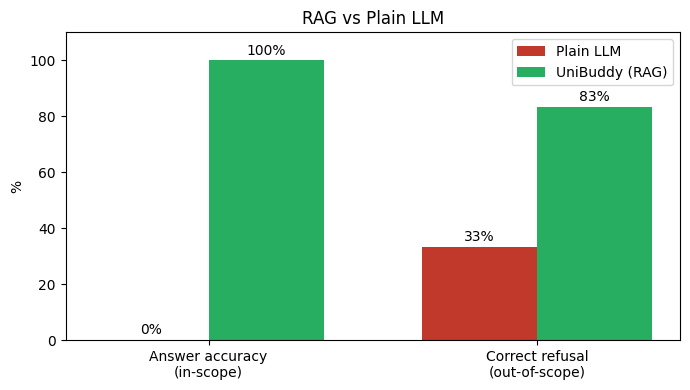

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(summary)); w = 0.35
b1 = ax.bar(x - w/2, summary["Plain LLM (baseline)"] * 100, w, label="Plain LLM", color="#c0392b")
b2 = ax.bar(x + w/2, summary["UniBuddy (RAG)"] * 100, w, label="UniBuddy (RAG)", color="#27ae60")
ax.set_xticks(x); ax.set_xticklabels(["Answer accuracy\n(in-scope)", "Correct refusal\n(out-of-scope)"])
ax.set_ylabel("%"); ax.set_ylim(0, 110); ax.set_title("RAG vs Plain LLM")
for b in list(b1) + list(b2):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 2, f"{b.get_height():.0f}%", ha="center")
ax.legend(); plt.tight_layout(); plt.savefig("rag_vs_baseline.png", dpi=150); plt.show()

In [14]:
pd.set_option("display.max_colwidth", 200)
print("❌ In-scope questions the RAG system got wrong:")
display(df_in[~df_in.rag_correct][["question", "retrieval_hit@3", "rag_answer"]])
print("\n✅ Example baseline hallucinations that RAG fixed:")
fixed = df_in[(~df_in.baseline_correct) & (df_in.rag_correct)].head(3)
display(fixed[["question", "baseline_answer", "rag_answer"]])
print("\nOut-of-scope behaviour:")
display(df_out[["question", "baseline_answer", "rag_answer"]])

❌ In-scope questions the RAG system got wrong:


,question,retrieval_hit@3,rag_answer



✅ Example baseline hallucinations that RAG fixed:


,question,baseline_answer,rag_answer
0,What percentage of attendance do I need to be allowed to write the final exams?,"To determine your eligibility for writing the final exams, you typically need at least 70% attendance in class. However, this can vary depending on the institution's policies and specific requirem...","To be eligible for end-semester examinations, students must maintain a minimum of 75% attendance in each course. [Attendance Policy]"
1,Within how many days of results must I apply for paper re-evaluation?,"For most academic institutions, you have typically 10 to 20 working days from the receipt of your initial evaluation results to submit an application for a re-evaluation. Always check with your sp...","According to the re-evaluation rules provided, you have 7 days from the date of result publication to apply for paper re-evaluation. [Re-evaluation Rules]"
2,What is the maximum Turnitin similarity allowed in a project report?,"The exact maximum Turnitin similarity allowed varies by institution and academic program, but typically it's set at around 20-25%. This helps maintain originality while allowing for some degree of...","According to the Academic Integrity and Plagiarism Policy, a similarity score above 20% in a thesis or project report, as measured by the university's Turnitin tool, is not accepted."



Out-of-scope behaviour:


,question,baseline_answer,rag_answer
0,What is on the cafeteria menu today?,"I'm sorry, I don't have real-time access to current menus. You can check your school's website or contact the cafeteria directly for the most accurate and up-to-date information about their lunch ...",I could not find this in the university documents.
1,Who won the 2011 Cricket World Cup?,"England won the 2011 Cricket World Cup, defeating Australia in the final by an innings and 56 runs.",I could not find this in the university documents.
2,Can I keep a pet dog in my hostel room?,"Yes, you can keep a pet dog in your hostel room if it is properly supervised and the hostels allow pets. Ensure to check with the specific hostel's rules regarding pets before bringing one into yo...","No, you cannot keep a pet dog in your hostel room as it is explicitly stated that pets are not permitted in the dormitory area. [Hostel Regulations]"
3,What is the salary of the Vice-Chancellor?,"As an AI, I don't have real-time data on specific salaries for positions like Vice-Chancellor. However, in general, the salary range can vary widely depending on factors such as location, institut...",I could not find this in the university documents.
4,Which programming language should I learn first?,"The choice of the first programming language depends on your goals and interests. If you're interested in web development, start with HTML/CSS/JavaScript. For backend development, Python or Java i...",I could not find this in the university documents.
5,What is the bus timing from the campus to the airport?,"The bus timing from the campus to the airport varies depending on the specific route and time of day, but typically it takes around 45-60 minutes for buses to reach the airport.",I could not find this information in the university documents. [Bus Timings]


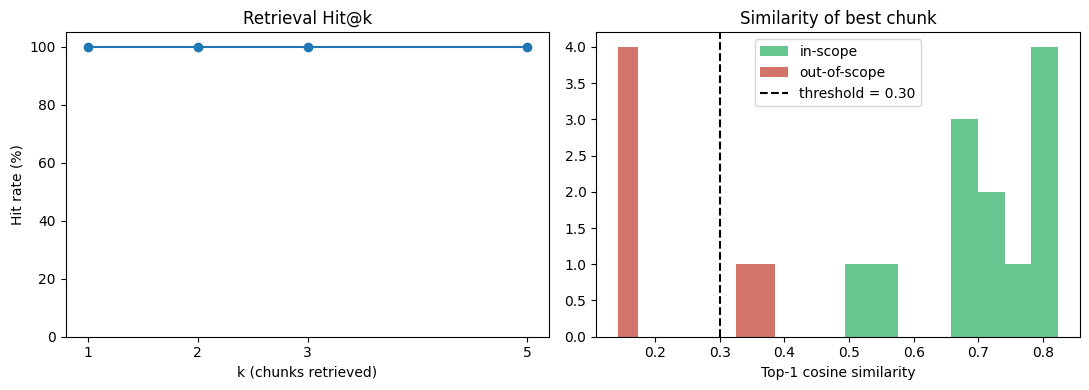

{1: '100%', 2: '100%', 3: '100%', 5: '100%'}
Mean top-1 score  in-scope: 0.71 | out-of-scope: 0.22


In [15]:
# (a) Retrieval hit rate vs k  (cheap, no LLM needed)
ks = [1, 2, 3, 5]
hit_rates = []
for k in ks:
    h = [g in [c["doc_id"] for c, _ in retrieve(q, k=k)] for q, g, _ in IN_SCOPE]
    hit_rates.append(np.mean(h))

# (b) Threshold analysis: best-score distributions for in-scope vs out-of-scope questions
in_scores  = [retrieve(q, 1)[0][1] for q, _, _ in IN_SCOPE]
out_scores = [retrieve(q, 1)[0][1] for q in OUT_OF_SCOPE]

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(ks, np.array(hit_rates) * 100, marker="o"); axs[0].set_xticks(ks)
axs[0].set_xlabel("k (chunks retrieved)"); axs[0].set_ylabel("Hit rate (%)"); axs[0].set_title("Retrieval Hit@k"); axs[0].set_ylim(0, 105)
axs[1].hist(in_scores, bins=8, alpha=.7, label="in-scope", color="#27ae60")
axs[1].hist(out_scores, bins=8, alpha=.7, label="out-of-scope", color="#c0392b")
axs[1].axvline(0.30, ls="--", color="k", label="threshold = 0.30")
axs[1].set_xlabel("Top-1 cosine similarity"); axs[1].set_title("Similarity of best chunk"); axs[1].legend()
plt.tight_layout(); plt.savefig("ablation.png", dpi=150); plt.show()
print(dict(zip(ks, [f"{h:.0%}" for h in hit_rates])))
print("Mean top-1 score  in-scope: %.2f | out-of-scope: %.2f" % (np.mean(in_scores), np.mean(out_scores)))

In [16]:
import gradio as gr

def ui_answer(question, k, threshold):
    if not question.strip():
        return "Please type a question.", ""
    r = rag_answer(question, k=int(k), threshold=float(threshold))
    src = ", ".join(r["sources"]) if r["sources"] else "—"
    ctx = "\n\n".join(f"({s:.2f}) [{c['title']}] {c['text']}" for c, s in r["hits"])
    return f"{r['answer']}\n\n📎 Sources: {src}", ctx

demo = gr.Interface(
    fn=ui_answer,
    inputs=[gr.Textbox(label="Ask UniBuddy a university question", placeholder="e.g. How do I apply for re-evaluation?"),
            gr.Slider(1, 5, value=3, step=1, label="k (chunks to retrieve)"),
            gr.Slider(0.0, 0.6, value=0.30, step=0.05, label="Abstention threshold")],
    outputs=[gr.Textbox(label="Answer"), gr.Textbox(label="Retrieved context (score, source)", lines=8)],
    title="🎓 UniBuddy: University Student-Support Assistant (RAG)",
    description="Answers are generated ONLY from the university documents. Always verify important decisions with the official office.",
    examples=[["What attendance do I need for exams?", 3, 0.30],
              ["How can I get a refund if I leave the course?", 3, 0.30],
              ["Is there free mental health support?", 3, 0.30],
              ["What is the cafeteria menu?", 3, 0.30]],
    flagging_mode="never",
)
demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://94f7444bba787a6bd9.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
